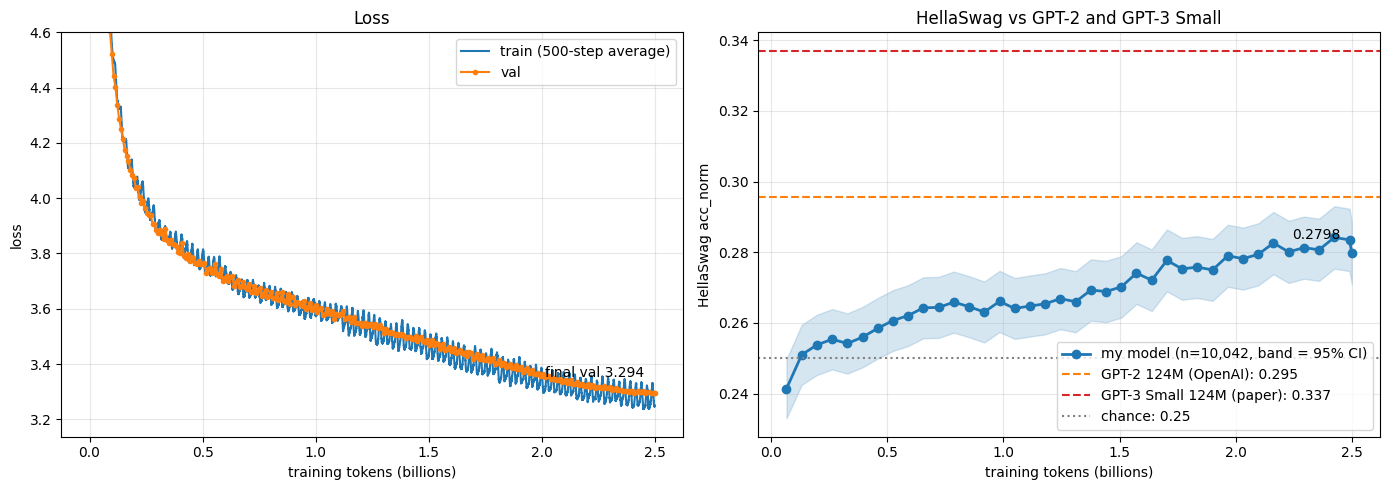

final val loss 3.2938 | final HellaSwag 0.2798 | best HellaSwag 0.2842 at step 74000


In [3]:
import numpy as np
import matplotlib.pyplot as plt

LOG = "log/log.txt"
TOKENS_PER_STEP = 32768
N_HELLA = 10042
REFS = {"GPT-2 124M (OpenAI)": 0.2955, "GPT-3 Small 124M (paper)": 0.337}

def read_series(kind):
    d = {}
    for line in open(LOG):
        p = line.split()
        if len(p) == 3 and p[1] == kind:
            d[int(p[0])] = float(p[2])          # later lines win (resume re-runs a step)
    s = np.array(sorted(d))
    return s, np.array([d[k] for k in s])

ts, tl = read_series("train")
vs, vl = read_series("val")
hs, hv = read_series("hella")
tok = lambda s: s * TOKENS_PER_STEP / 1e9       # steps -> billions of tokens

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# left: loss
w = min(500, len(tl))
sm = np.convolve(tl, np.ones(w) / w, mode="valid")
ax[0].plot(tok(ts[w - 1:]), sm, lw=1.5, label=f"train ({w}-step average)")
ax[0].plot(tok(vs), vl, "o-", ms=3, lw=1.5, label="val")
ax[0].set_ylim(min(vl.min(), sm.min()) - 0.1, 4.6)
ax[0].set_xlabel("training tokens (billions)")
ax[0].set_ylabel("loss")
ax[0].set_title("Loss")
ax[0].annotate(f"final val {vl[-1]:.3f}", (tok(vs[-1]), vl[-1]),
               textcoords="offset points", xytext=(-8, 12), ha="right")
ax[0].grid(alpha=0.3)
ax[0].legend()

# right: HellaSwag vs references
se = np.sqrt(hv * (1 - hv) / N_HELLA)
ax[1].plot(tok(hs), hv, "o-", lw=2, color="tab:blue", label=f"my model (n={N_HELLA:,}, band = 95% CI)")
ax[1].fill_between(tok(hs), hv - 1.96 * se, hv + 1.96 * se, color="tab:blue", alpha=0.18)
for (name, v), c in zip(REFS.items(), ["tab:orange", "tab:red"]):
    ax[1].axhline(v, ls="--", color=c, label=f"{name}: {v:.3f}")
ax[1].axhline(0.25, ls=":", color="gray", label="chance: 0.25")
ax[1].annotate(f"{hv[-1]:.4f}", (tok(hs[-1]), hv[-1]),
               textcoords="offset points", xytext=(-8, 10), ha="right")
ax[1].set_xlabel("training tokens (billions)")
ax[1].set_ylabel("HellaSwag acc_norm")
ax[1].set_title("HellaSwag vs GPT-2 and GPT-3 Small")
ax[1].grid(alpha=0.3)
ax[1].legend(loc="lower right")

plt.tight_layout()
plt.savefig("log/training_summary.png", dpi=140)
plt.show()
print(f"final val loss {vl[-1]:.4f} | final HellaSwag {hv[-1]:.4f} | best HellaSwag {hv.max():.4f} at step {hs[hv.argmax()]}")

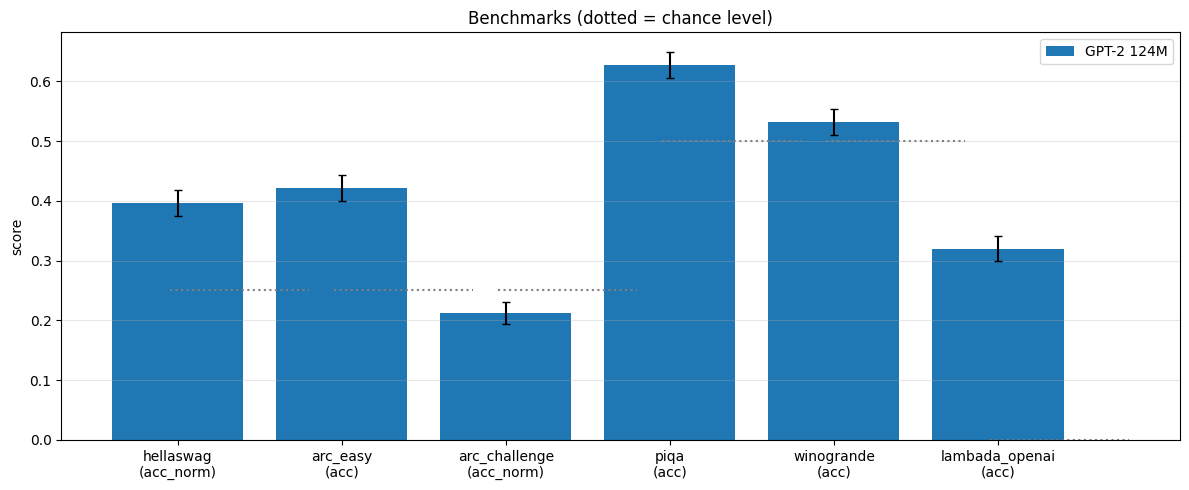

In [4]:
import json, glob

rows = {r["name"]: r for r in (json.load(open(p)) for p in glob.glob("results/*.json"))}
order = [("model_final", "My model (2.5B tokens)"),
         ("gpt2-openai-124M", "GPT-2 124M"),
         ("GPT-3 Small 125M (paper)", "GPT-3 Small (paper)")]   # optional file from earlier
sel = [(rows[k], lbl) for k, lbl in order if k in rows]

tasks = {"hellaswag": "acc_norm", "arc_easy": "acc", "arc_challenge": "acc_norm",
         "piqa": "acc", "winogrande": "acc", "lambada_openai": "acc"}
chance = {"hellaswag": .25, "arc_easy": .25, "arc_challenge": .25, "piqa": .5, "winogrande": .5, "lambada_openai": 0}

x = np.arange(len(tasks))
width = 0.8 / len(sel)
fig, ax = plt.subplots(figsize=(12, 5))
for i, (r, lbl) in enumerate(sel):
    lm = r.get("lm_eval", {})
    vals = [lm.get(t, {}).get(m, np.nan) for t, m in tasks.items()]
    errs = [lm.get(t, {}).get(m + "_stderr", 0) for t, m in tasks.items()]
    ax.bar(x + i * width, vals, width, yerr=errs, capsize=3, label=lbl)
for j, t in enumerate(tasks):
    ax.hlines(chance[t], j - 0.05, j + 0.8, colors="gray", linestyles=":")
ax.set_xticks(x + width * (len(sel) - 1) / 2)
ax.set_xticklabels([f"{t}\n({m})" for t, m in tasks.items()])
ax.set_ylabel("score")
ax.set_title("Benchmarks (dotted = chance level)")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("results/benchmarks.png", dpi=140)
plt.show()


In [5]:
import torch, tiktoken, torch.nn.functional as F
from evals import load_ours                      # reuses your checkpoint loader
enc = tiktoken.get_encoding("gpt2")
dev = "cuda" if torch.cuda.is_available() else "cpu"
model, _ = load_ours("log/model_final.pt"); model.to(dev).eval()

GPT(
  (transformer): ModuleDict(
    (wte): Embedding(50304, 768)
    (wpe): Embedding(1024, 768)
    (h): ModuleList(
      (0-11): 12 x Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): CausalSelfAttention(
          (c_attn): Linear(in_features=768, out_features=2304, bias=True)
          (c_proj): Linear(in_features=768, out_features=768, bias=True)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): MLP(
          (c_fc): Linear(in_features=768, out_features=3072, bias=True)
          (gelu): GELU(approximate='tanh')
          (c_proj): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (lm_head): Linear(in_features=768, out_features=50304, bias=False)
)

In [6]:
@torch.no_grad()
def top_next(prompt, k=10):
    x = torch.tensor([enc.encode(prompt)], device=dev)
    p = F.softmax(model(x)[0][0, -1, :50257].float(), -1)
    for pr, t in zip(*[v.tolist() for v in p.topk(k)]):
        print(f"{pr:6.1%}  {enc.decode([t])!r}")

top_next("The capital of France is")
top_next("2 + 2 =")
top_next("Once upon a time, there was a")

  9.9%  ' the'
  8.0%  ' Paris'
  5.6%  ' located'
  4.0%  ' also'
  2.9%  ' now'
  2.8%  ' Saint'
  2.0%  ' in'
  1.5%  ' La'
  1.3%  ' at'
  1.2%  ' a'
 13.6%  ' 2'
 12.2%  ' 0'
 11.3%  ' 1'
  5.6%  ' -'
  5.6%  ' 4'
  4.1%  ' 3'
  2.8%  ' 10'
  2.1%  ' 5'
  2.0%  ' ('
  2.0%  ' 8'
  5.3%  ' time'
  3.4%  ' man'
  3.2%  ' great'
  1.5%  ' large'
  1.4%  ' race'
  1.3%  ' small'
  1.3%  ' king'
  1.2%  ' certain'
  1.1%  ' very'
  0.9%  ' huge'


In [7]:
import html
from IPython.display import HTML, display

@torch.no_grad()
def surprise(text):
    ids = enc.encode(text)
    x = torch.tensor([ids], device=dev)
    lp = F.log_softmax(model(x)[0][0, :-1, :50257].float(), -1)
    nll = (-lp.gather(1, x[0, 1:, None])[:, 0]).tolist()
    out = [html.escape(enc.decode([ids[0]]))]
    for t, l in zip(ids[1:], nll):
        out.append(f"<span style='background:rgba(255,80,80,{min(l/10, 1):.2f})' title='{l:.1f} nats'>"
                   f"{html.escape(enc.decode([t]))}</span>")
    display(HTML("<div style='font-family:monospace;white-space:pre-wrap'>" + "".join(out) + "</div>"))

surprise("Photosynthesis is the process by which plants convert sunlight into energy. Banana turbine.")

In [8]:
@torch.no_grad()
def induction_gap(m, n=64, L=50, seed=0):
    g = torch.Generator().manual_seed(seed)
    r = torch.randint(0, 50000, (n, L), generator=g)
    x = torch.cat([r, r], 1).to(dev)
    logits = m(x)[0][:, :-1, :50257].float()
    ce = F.cross_entropy(logits.transpose(1, 2), x[:, 1:], reduction="none")
    return ce[:, :L-1].mean().item(), ce[:, L:].mean().item()

import glob
for p in sorted(glob.glob("log/model_*.pt")):
    m, _ = load_ours(p); m.to(dev).eval()
    a, b = induction_gap(m)
    print(f"{p:28s} random block {a:5.2f} -> repeated block {b:5.2f}")

log/model_05000.pt           random block 12.80 -> repeated block  7.26
log/model_10000.pt           random block 12.74 -> repeated block  6.49
log/model_15000.pt           random block 12.61 -> repeated block  3.87
log/model_20000.pt           random block 12.46 -> repeated block  4.07
log/model_25000.pt           random block 12.56 -> repeated block  4.12
log/model_30000.pt           random block 12.73 -> repeated block  4.19
log/model_35000.pt           random block 13.11 -> repeated block  4.29
log/model_40000.pt           random block 12.71 -> repeated block  3.58
log/model_45000.pt           random block 12.65 -> repeated block  3.82
log/model_50000.pt           random block 12.66 -> repeated block  3.86
log/model_55000.pt           random block 12.75 -> repeated block  3.66
log/model_60000.pt           random block 12.53 -> repeated block  4.02
log/model_65000.pt           random block 12.55 -> repeated block  4.18
log/model_70000.pt           random block 12.48 -> repeated bloc

In [9]:
from lab import *
load("log/model_final.pt")

loaded log/model_final.pt (step 76293) on cuda


GPT(
  (transformer): ModuleDict(
    (wte): Embedding(50304, 768)
    (wpe): Embedding(1024, 768)
    (h): ModuleList(
      (0-11): 12 x Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): CausalSelfAttention(
          (c_attn): Linear(in_features=768, out_features=2304, bias=True)
          (c_proj): Linear(in_features=768, out_features=768, bias=True)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): MLP(
          (c_fc): Linear(in_features=768, out_features=3072, bias=True)
          (gelu): GELU(approximate='tanh')
          (c_proj): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (lm_head): Linear(in_features=768, out_features=50304, bias=False)
)

In [20]:
peek("The capital of France is")
peek("Once upon a time, there was a")

prompt: 'The capital of France is'
    9.9%  ' the'
    8.0%  ' Paris'
    5.6%  ' located'
    4.0%  ' also'
    2.9%  ' now'
    2.8%  ' Saint'
    2.0%  ' in'
    1.5%  ' La'
    1.3%  ' at'
    1.2%  ' a'
prompt: 'Once upon a time, there was a'
    5.3%  ' time'
    3.4%  ' man'
    3.2%  ' great'
    1.5%  ' large'
    1.4%  ' race'
    1.3%  ' small'
    1.3%  ' king'
    1.2%  ' certain'
    1.1%  ' very'
    0.9%  ' huge'


In [21]:
surprise("Photosynthesis is the process by which plants convert sunlight into energy. Banana turbine.")

In [26]:
for name, t in {
    "science": "Every single atom in your body was forged inside the fiery core of a dying star billions of years ago. When massive stars run out of fuel, they explode in violent supernovas, scattering essential elements like carbon, nitrogen, and oxygen across the cosmos. Over eons, gravity pulled these drifting clouds of stardust together to form new solar systems, our planet, and eventually, all life on Earth. This means that quite literally, you are made of stardust.",
    "story": "Arthur reached into his coat pocket and pulled out a brass pocket watch that had stopped ticking the exact minute the rain had started. Across the cobblestone street, a yellow neon sign flickered to life outside a small shop, casting long, warped shadows over the puddles. He didn't know who had left the handwritten note under his apartment door, or why it contained only a single coordinate and a sketch of a blue umbrella, but as the distant train whistle blew through the fog, he knew he had only minutes left to decide whether to walk toward the station or turn back home.",
    "code": "def add(a, b):\n    return a + b",
    "hindi": "शाम के समय जब सूरज की सुनहरी किरणें पहाड़ों के पीछे छिपने लगीं, तो पूरे गाँव में एक शांत और सुहावना माहौल छा गया। ठंडी हवा के झोंके पेड़ों की पत्तियों से टकराकर एक मीठी सी सरसराहट पैदा कर रहे थे, और पक्षी अपने घोंसलों की ओर लौट रहे थे। ऐसे सुकून भरे पल में, आँगन में बैठकर गर्म चाय की चुस्की लेना दिन भर की सारी थकान को पल भर में दूर कर देता है। \n क्या आप इस अनुच्छेद का अंग्रेजी अनुवाद चाहेंगे, या किसी खास विषय (जैसे प्रकृति, प्रेरणा, या त्योहार) पर एक नया हिंदी अनुच्छेद लिखवाना चाहेंगे? "}.items(): 
    print(name, round(text_loss(t), 2))

science 3.23
story 4.08
code 4.59
hindi 1.89


In [31]:

import math
import pandas as pd

tests = {
    "English": [
        "The Earth revolves around the Sun once every 365.25 days. This orbital motion determines the length of a year and contributes to seasonal changes.",
        "Neural networks learn patterns by adjusting their parameters through gradient descent. The quality of their predictions depends on their architecture, training data and optimization.",
        "The human brain contains billions of neurons connected through complex networks. These connections allow it to process information, learn and form memories.",
    ],
    "Science": [
        "Every atom consists of a nucleus containing protons and neutrons, surrounded by electrons. The number of protons determines the chemical element.",
        "Photosynthesis converts light energy into chemical energy. Plants use carbon dioxide and water to produce glucose and release oxygen.",
        "Black holes are regions of spacetime where gravity is so strong that nothing, including light, can escape beyond the event horizon.",
    ],
    "Story": [
        "The old man opened the wooden door and stepped into the empty room. A clock on the wall continued ticking, although its hands had not moved in years.",
        "Maya watched the last train disappear into the darkness. She unfolded the letter again, hoping that the words might somehow have changed.",
        "Rain fell against the windows as the detective examined the photograph. Something about the reflection in the mirror seemed strangely familiar.",
    ],
    "Code": [
        "def factorial(n):\n    if n <= 1:\n        return 1\n    return n * factorial(n - 1)",
        "class Stack:\n    def __init__(self):\n        self.items = []\n    def push(self, value):\n        self.items.append(value)\n    def pop(self):\n        return self.items.pop()",
        "def binary_search(arr, target):\n    left, right = 0, len(arr) - 1\n    while left <= right:\n        mid = (left + right) // 2\n        if arr[mid] == target:\n            return mid\n        if arr[mid] < target:\n            left = mid + 1\n        else:\n            right = mid - 1\n    return -1",
    ],
    "Hindi": [
        "भारत एक विविधताओं से भरा देश है। यहाँ अनेक भाषाएँ, संस्कृतियाँ और परंपराएँ एक साथ विकसित हुई हैं।",
        "शिक्षा व्यक्ति के जीवन में महत्वपूर्ण भूमिका निभाती है। यह हमें सोचने, समझने और समस्याओं का समाधान करने की क्षमता प्रदान करती है।",
        "प्रकृति हमारे जीवन का आधार है। पेड़, नदियाँ, पहाड़ और वन्यजीव पर्यावरण का संतुलन बनाए रखने में महत्वपूर्ण योगदान देते हैं।",
    ],
}

rows = []

for domain, samples in tests.items():
    total_nll = 0.0
    total_tokens = 0
    total_bytes = 0

    for text in samples:
        ids, nll = token_losses(text)

        # token_losses predicts every token after the first
        target_ids = ids[1:]

        total_nll += sum(nll)
        total_tokens += len(nll)
        total_bytes += sum(
            len(enc.decode_single_token_bytes(t))
            for t in target_ids
        )

    avg_nll = total_nll / total_tokens
    ppl = math.exp(avg_nll)
    bpb = total_nll / (total_bytes * math.log(2))

    rows.append({
        "domain": domain,
        "loss_nats/token": avg_nll,
        "perplexity": ppl,
        "bits/byte": bpb,
        "tokens": total_tokens,
        "bytes": total_bytes,
    })

results = pd.DataFrame(rows)
print(results.to_string(index=False))


 domain  loss_nats/token  perplexity  bits/byte  tokens  bytes
English         3.343577   28.320246   0.790448      78    476
Science         2.532053   12.579300   0.659953      71    393
  Story         4.464076   86.840726   1.183540      77    419
   Code         2.928696   18.703217   2.080839     262    532
  Hindi         1.831996    6.246345   1.576534     544    912


In [27]:
sampling_lab("The scientist opened the door and")

--- temperature 0 ---
The scientist opened the door and said, “I am a scientist.”
“I am a scientist,” said the scientist. “I am a scientist.”
“I am a scientist,” said the scientist. “

--- temperature 0.4 ---
The scientist opened the door and the scientists were able to open the door and the scientists were able to open the door.
The scientists were able to open the door and the scientists were able to open the door and the scientists were able to open the door.
The scientists were

--- temperature 0.8 ---
The scientist opened the door and asked "What is it that causes the loss of my child?" The question was, "Does the child have a parent who has Alzheimer's disease?"
The question was, "Does anyone in the community have Alzheimer's disease?"
Some question marks

--- temperature 1.2 ---
The scientist opened the door and showed off the two of the new metal fragments on their way to a metal mill (called Cymru) in which he said that he had created what he thought was a metal-block that he 

In [28]:
score("The capital of France is", [" Paris", " London", " banana"])
score("Water freezes at", [" 0 degrees Celsius", " 100 degrees Celsius", " purple"])

prompt: 'The capital of France is'
  avg  -2.520 | total    -2.52 | ' Paris'
  avg  -6.859 | total    -6.86 | ' London'
  avg -15.987 | total   -15.99 | ' banana'
prompt: 'Water freezes at'
  avg  -2.638 | total    -7.91 | ' 100 degrees Celsius'
  avg  -2.668 | total    -8.00 | ' 0 degrees Celsius'
  avg -13.518 | total   -13.52 | ' purple'


[(' 100 degrees Celsius', -7.913010597229004, -2.6376702785491943),
 (' 0 degrees Celsius', -8.003291130065918, -2.6677637100219727),
 (' purple', -13.518298149108887, -13.518298149108887)]

step   5000  first copy  12.80   repeated copy   7.26
step  10000  first copy  12.74   repeated copy   6.49
step  15000  first copy  12.61   repeated copy   3.87
step  20000  first copy  12.46   repeated copy   4.07
step  25000  first copy  12.56   repeated copy   4.12
step  30000  first copy  12.73   repeated copy   4.19
step  35000  first copy  13.11   repeated copy   4.29
step  40000  first copy  12.71   repeated copy   3.58
step  45000  first copy  12.65   repeated copy   3.82
step  50000  first copy  12.66   repeated copy   3.86
step  55000  first copy  12.75   repeated copy   3.66
step  60000  first copy  12.53   repeated copy   4.02
step  65000  first copy  12.55   repeated copy   4.18
step  70000  first copy  12.48   repeated copy   3.91
step  75000  first copy  12.52   repeated copy   3.74


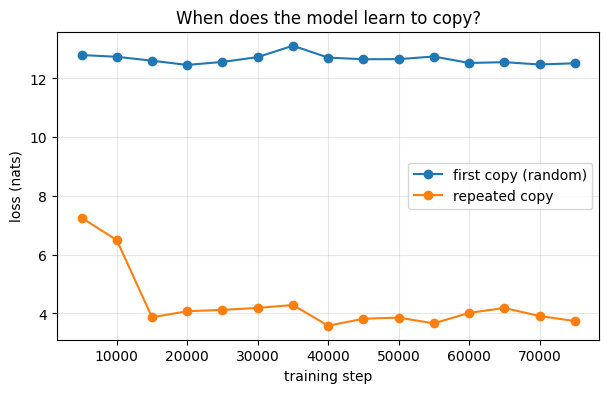

[(5000, 12.797628402709961, 7.257359027862549),
 (10000, 12.737967491149902, 6.492945194244385),
 (15000, 12.605172157287598, 3.8683974742889404),
 (20000, 12.460408210754395, 4.073336601257324),
 (25000, 12.563102722167969, 4.119919776916504),
 (30000, 12.727174758911133, 4.18674898147583),
 (35000, 13.114808082580566, 4.286853313446045),
 (40000, 12.709795951843262, 3.580519914627075),
 (45000, 12.654932975769043, 3.818449020385742),
 (50000, 12.657715797424316, 3.8564982414245605),
 (55000, 12.747518539428711, 3.6608800888061523),
 (60000, 12.526856422424316, 4.016740322113037),
 (65000, 12.554994583129883, 4.184909820556641),
 (70000, 12.476656913757324, 3.909914255142212),
 (75000, 12.516133308410645, 3.7406041622161865)]

In [29]:
copy_over_training()

baseline val loss: 3.3114
  skip layer  0: loss +7.539
  skip layer  1: loss +2.907
  skip layer  2: loss +0.255
  skip layer  3: loss +0.172
  skip layer  4: loss +0.133
  skip layer  5: loss +0.139
  skip layer  6: loss +0.377
  skip layer  7: loss +0.736
  skip layer  8: loss +0.317
  skip layer  9: loss +0.285
  skip layer 10: loss +0.491
  skip layer 11: loss +0.737


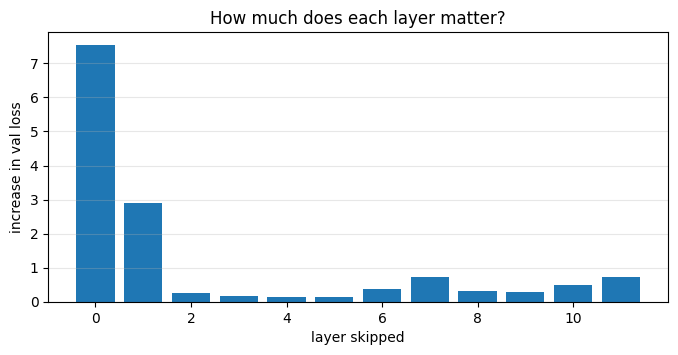

[7.539000000000001,
 2.9065000000000003,
 0.25459999999999994,
 0.1724000000000001,
 0.1333000000000002,
 0.13870000000000005,
 0.3770000000000002,
 0.7355,
 0.3174000000000001,
 0.2854000000000001,
 0.4908000000000001,
 0.7366000000000001]

In [30]:
layer_ablation()

In [33]:

import torch

path = "/home/azureuser/gpt2/log/model_final.pt"

ckpt = torch.load(path, map_location="cpu", weights_only=False)

print("Checkpoint keys:", ckpt.keys())

state = ckpt.get("model", ckpt)
print("\nFirst 40 model parameters:")
for key in list(state.keys())[:40]:
    print(key, tuple(state[key].shape))


Checkpoint keys: dict_keys(['model', 'config', 'step', 'val_loss'])

First 40 model parameters:
transformer.wte.weight (50304, 768)
transformer.wpe.weight (1024, 768)
transformer.h.0.ln_1.weight (768,)
transformer.h.0.ln_1.bias (768,)
transformer.h.0.attn.c_attn.weight (2304, 768)
transformer.h.0.attn.c_attn.bias (2304,)
transformer.h.0.attn.c_proj.weight (768, 768)
transformer.h.0.attn.c_proj.bias (768,)
transformer.h.0.ln_2.weight (768,)
transformer.h.0.ln_2.bias (768,)
transformer.h.0.mlp.c_fc.weight (3072, 768)
transformer.h.0.mlp.c_fc.bias (3072,)
transformer.h.0.mlp.c_proj.weight (768, 3072)
transformer.h.0.mlp.c_proj.bias (768,)
transformer.h.1.ln_1.weight (768,)
transformer.h.1.ln_1.bias (768,)
transformer.h.1.attn.c_attn.weight (2304, 768)
transformer.h.1.attn.c_attn.bias (2304,)
transformer.h.1.attn.c_proj.weight (768, 768)
transformer.h.1.attn.c_proj.bias (768,)
transformer.h.1.ln_2.weight (768,)
transformer.h.1.ln_2.bias (768,)
transformer.h.1.mlp.c_fc.weight (3072, 768)
tr

In [38]:

import torch
from transformers import GPT2LMHeadModel

device = "cuda"

# Load your original model
original = GPT2LMHeadModel.from_pretrained(
    "/home/azureuser/gpt2/hf_model",
    torch_dtype=torch.float32
).to(device).eval()

# Reload checkpoint directly for comparison
ckpt = torch.load(
    "/home/azureuser/gpt2/log/model_final.pt",
    map_location="cpu",
    weights_only=False
)

# Build converted state dict
state = ckpt["model"]
converted = {}

for key, value in state.items():
    if key.endswith((
        "attn.c_attn.weight",
        "attn.c_proj.weight",
        "mlp.c_fc.weight",
        "mlp.c_proj.weight",
    )):
        value = value.T.contiguous()
    converted[key] = value

# Compare saved and freshly converted model
fresh = GPT2LMHeadModel(original.config).to(device).eval()
fresh.load_state_dict(converted, strict=True)

# Same token IDs, same model configuration
input_ids = torch.tensor(
    [[15496, 11, 995, 318, 257, 1332]],
    device=device
)

with torch.no_grad():
    logits_saved = original(input_ids).logits
    logits_fresh = fresh(input_ids).logits

print("Maximum absolute difference:",
      (logits_saved - logits_fresh).abs().max().item())

print("Equivalent:",
      torch.allclose(logits_saved, logits_fresh, atol=1e-5, rtol=1e-4))


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Maximum absolute difference: 0.0
Equivalent: True


In [37]:

import torch
from transformers import GPT2Config, GPT2LMHeadModel, AutoTokenizer

CHECKPOINT = "/home/azureuser/gpt2/log/model_final.pt"
OUTPUT = "/home/azureuser/gpt2/hf_model"

ckpt = torch.load(CHECKPOINT, map_location="cpu", weights_only=False)

state = ckpt["model"]
cfg = ckpt["config"]

config = GPT2Config(
    vocab_size=cfg["vocab_size"],
    n_positions=cfg["block_size"],
    n_ctx=cfg["block_size"],
    n_embd=cfg["n_embd"],
    n_layer=cfg["n_layer"],
    n_head=cfg["n_head"],
    n_inner=4 * cfg["n_embd"],
    activation_function="gelu",
    resid_pdrop=0.0,
    embd_pdrop=0.0,
    attn_pdrop=0.0,
    layer_norm_epsilon=1e-5,
    scale_attn_weights=True,
    tie_word_embeddings=True,
)

model = GPT2LMHeadModel(config)

converted = {}

for key, value in state.items():

    # Hugging Face GPT-2 uses Conv1D for these projections.
    # Your model uses nn.Linear, so transpose their weights.
    if key.endswith((
        "attn.c_attn.weight",
        "attn.c_proj.weight",
        "mlp.c_fc.weight",
        "mlp.c_proj.weight",
    )):
        value = value.T.contiguous()

    converted[key] = value

expected = model.state_dict()

for key in expected:
    assert key in converted, f"Missing: {key}"
    assert expected[key].shape == converted[key].shape, (
        key, expected[key].shape, converted[key].shape
    )

result = model.load_state_dict(converted, strict=True)
print(result)

tokenizer = AutoTokenizer.from_pretrained("openai-community/gpt2")

model.save_pretrained(OUTPUT, safe_serialization=True)
tokenizer.save_pretrained(OUTPUT)

print("Conversion successful!")
print("Parameters:", sum(p.numel() for p in model.parameters()))
print("Saved to:", OUTPUT)


<All keys matched successfully>


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Conversion successful!
Parameters: 124475904
Saved to: /home/azureuser/gpt2/hf_model


In [40]:

import torch
import math
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM

device = "cuda"
SEQ_LEN = 1024
STRIDE = 512

dataset = load_dataset(
    "Salesforce/wikitext",
    "wikitext-103-raw-v1",
    split="test"
)

tokenizer = AutoTokenizer.from_pretrained(
    "/home/azureuser/gpt2/hf_model"
)

def encode_documents(dataset):
    documents = []

    for text in dataset["text"]:
        if not text.strip():
            continue

        ids = tokenizer(
            text,
            add_special_tokens=False
        )["input_ids"]

        if len(ids) >= 2:
            documents.append(torch.tensor(ids, dtype=torch.long))

    return documents

documents = encode_documents(dataset)

def evaluate(path):
    model = AutoModelForCausalLM.from_pretrained(
        path,
        torch_dtype=torch.float16
    ).to(device).eval()

    total_nll = 0.0
    total_tokens = 0

    with torch.no_grad():
        for doc in documents:
            doc = doc.to(device)

            # Every target token is counted once.
            for target_start in range(1, len(doc), STRIDE):
                target_end = min(
                    target_start + STRIDE,
                    len(doc)
                )

                context_start = max(
                    0,
                    target_end - SEQ_LEN
                )

                input_ids = doc[
                    context_start:target_end
                ].unsqueeze(0)

                logits = model(input_ids).logits

                # Predict targets from target_start onwards.
                local_start = target_start - context_start

                start_logits = local_start - 1
                end_logits = input_ids.size(1) - 1

                if start_logits < 0:
                    continue

                target_logits = logits[
                    :,
                    start_logits:end_logits,
                    :
                ]

                targets = input_ids[
                    :,
                    local_start:
                ]

                nll = torch.nn.functional.cross_entropy(
                    target_logits.float().reshape(
                        -1, target_logits.size(-1)
                    ),
                    targets.reshape(-1),
                    reduction="sum"
                )

                total_nll += nll.item()
                total_tokens += targets.numel()

    del model
    torch.cuda.empty_cache()

    avg_nll = total_nll / total_tokens

    return {
        "nll": avg_nll,
        "perplexity": math.exp(avg_nll),
        "tokens": total_tokens
    }

print("Your model:", evaluate(
    "/home/azureuser/gpt2/hf_model"
))

print("GPT-2:", evaluate(
    "openai-community/gpt2"
))


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Your model: {'nll': 4.409486104922382, 'perplexity': 82.22719649320324, 'tokens': 280396}


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT-2: {'nll': 3.9047187903728067, 'perplexity': 49.636119794666634, 'tokens': 280396}
